<div style="text-align:center">
  <img src="logo.png" alt="Логотип курса" width="520">
</div>

# Альтернативная домашняя работа — неделя 1

## Распределения, описательные статистики и визуализация

Эта работа закрепляет темы [первой недели курса](https://github.com/FUlyankin/matstat-AB/tree/main/week01_intro), но содержит новые задания, которые не повторяют исходную домашнюю работу.

После каждого задания оставлена пустая кодовая ячейка. Ответ для самопроверки спрятан под раскрывающимся блоком: сначала выполните задание самостоятельно и только потом сравните результат.

## Что будет отработано

- поиск и оценка пропусков;
- среднее, медиана и влияние выбросов;
- размах, стандартное отклонение, квантили и межквартильный размах;
- фильтрация, группировка и агрегирование;
- создание производного показателя;
- гистограмма, boxplot и тепловая карта корреляций;
- воспроизводимая симуляция случайной величины.

## 1. Данные

В таблице используются следующие колонки:

- `title` — название видео;
- `commentCount` — количество комментариев;
- `dislikeCount` — количество дизлайков;
- `likeCount` — количество лайков;
- `music_style` — музыкальный жанр;
- `performer` — исполнитель;
- `viewCount` — количество просмотров;
- `commentators_uniq` — количество уникальных комментаторов;
- `comments_obscene_cnt` — количество нецензурных комментариев;
- `video_age` — возраст видео в днях на 15 марта 2019 года.

### Подготовка окружения

Выполните следующие две ячейки перед началом работы. Они подключают библиотеки и загружают исходные данные в переменную `df`.

In [111]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
%matplotlib inline

In [112]:
data_path = Path("data/youtube_data_short.csv")
if not data_path.exists():
    raise FileNotFoundError(f"Не найден файл данных: {data_path.resolve()}")

df = pd.read_csv(data_path, sep="\t")
df.head()

,title,commentCount,dislikeCount,likeCount,music_style,performer,viewCount,commentators_uniq,comments_obscene_cnt,video_age
0,"""#2Маши ""Свободные линии""",34.00,43.00,"1,402.00",popsa,2маши,"214,301.00",24.00,0.00,1141
1,"""ALARM"" СЕРГЕЙ ЛАЗАРЕВ ( SERGEY LAZAREV )",NaN,690.00,"10,532.00",popsa,лазарев,"2,221,419.00",NaN,NaN,3217
2,"""EARTH SONG"" SERGEY LAZAREV. DEDICATED TO MIC...",26.00,10.00,269.00,popsa,лазарев,"40,327.00",23.00,0.00,3546
3,"""Earth song"" премия МУЗ-тВ 2010 (LIVE)",12.00,7.00,163.00,popsa,лазарев,"11,907.00",11.00,0.00,3189
4,"""FAKE"" СЕРГЕЙ ЛАЗАРЕВ (SERGEY)",46.00,19.00,597.00,popsa,лазарев,"91,483.00",33.00,1.00,3361


## 2. Правила выполнения

1. Решение каждого задания пишите в пустой ячейке непосредственно под условием.
2. Числа выводите с понятными подписями; большие значения отделяйте пробелами или запятыми.
3. У каждого графика должны быть заголовок и подписи осей.
4. После расчёта сформулируйте краткий содержательный вывод там, где он запрошен.
5. Перед сдачей перезапустите ядро и выполните все ячейки сверху вниз.

## Задание 1. Аудит пропусков

Для каждой колонки определите количество и процент пропущенных значений. Дополнительно найдите общее число пропусков во всей таблице и назовите колонки с наибольшей долей пропусков.

Используйте все колонки набора данных. Процент округлите до двух знаков после запятой.

In [113]:
pr = df.isnull().sum()
dol_pr = round((pr / len(df)) * 100, 2)

print(pd.DataFrame({"Пропусков": pr, "Доля, %": dol_pr,}))
print()
print(f'Всего пропусков: {pr.sum()}')
print()
print('Максимальное количество пропусков:', end = ' ')
print(*dol_pr[dol_pr == dol_pr.max()].index)

                      Пропусков  Доля, %
title                         0     0.00
commentCount                210     1.10
dislikeCount                274     1.43
likeCount                   274     1.43
music_style                   0     0.00
performer                     0     0.00
viewCount                     1     0.01
commentators_uniq          6810    35.61
comments_obscene_cnt       6810    35.61
video_age                     0     0.00

Всего пропусков: 14379

Максимальное количество пропусков: commentators_uniq comments_obscene_cnt


<details>
<summary><strong>Результат для самопроверки</strong></summary>

| Колонка | Пропусков | Доля пропусков |
|---|---:|---:|
| `title` | 0 | 0,00% |
| `commentCount` | 210 | 1,10% |
| `dislikeCount` | 274 | 1,43% |
| `likeCount` | 274 | 1,43% |
| `music_style` | 0 | 0,00% |
| `performer` | 0 | 0,00% |
| `viewCount` | 1 | 0,01% |
| `commentators_uniq` | 6 810 | 35,61% |
| `comments_obscene_cnt` | 6 810 | 35,61% |
| `video_age` | 0 | 0,00% |

Всего в таблице 14 379 пропусков. Наибольшая доля пропусков одновременно у `commentators_uniq` и `comments_obscene_cnt` — 35,61%.

</details>

## Задание 2. Среднее против медианы

Для колонки `viewCount` — количество просмотров видео — найдите число непустых наблюдений, среднее и медиану. Определите, во сколько раз среднее больше медианы, и объясните, что такое различие говорит о форме распределения просмотров.

In [114]:
mediana = df.viewCount.median()
srednee = round(df.viewCount.mean(), 2)
print(f'Непустых наблюдений: {df.viewCount.notnull().sum()}')
print(f'Медиана: {mediana}')
print(f'Среднее: {srednee}')
print(f'Среднее больше медиана в {round(srednee / mediana, 2)}')

Непустых наблюдений: 19123
Медиана: 11353.0
Среднее: 843648.59
Среднее больше медиана в 74.31


<details>
<summary><strong>Результат для самопроверки</strong></summary>

- непустых значений: 19 123;
- среднее: 843 648,59 просмотра;
- медиана: 11 353 просмотра;
- среднее больше медианы примерно в 74,31 раза.

Такой разрыв указывает на сильную правостороннюю асимметрию: небольшое число чрезвычайно популярных видео сильно увеличивает среднее.

</details>

## Задание 3. Центр и разброс возраста видео

Для колонки `video_age` — возраст видео в днях — рассчитайте минимум, первый квартиль, медиану, среднее, третий квартиль, максимум, размах, выборочное стандартное отклонение и межквартильный размах.

По результатам сравните среднее с медианой и сделайте короткий вывод о распределении возраста видео.

In [115]:
print(f'Минимум: {df.video_age.min()}')
print(f'Первый квантиль: {df.video_age.quantile(0.25)}')
print(f'Медиана: {df.video_age.median()}')
print(f'Среднее: {df.video_age.mean()}')
print(f'Третий квантиль: {df.video_age.quantile(0.75)}')
print(f'Максимум: {df.video_age.max()}')
print(f'Размах: {df.video_age.max() - df.video_age.min()}')
print(f'Выборочное стандартное отклонение: {df.video_age.std()}')
print(f'Межквартильный размах: {df.video_age.quantile(0.75) - df.video_age.quantile(0.25)}')

Минимум: 0
Первый квантиль: 378.0
Медиана: 1213.0
Среднее: 1389.7726417067558
Третий квантиль: 2218.0
Максимум: 4574
Размах: 4574
Выборочное стандартное отклонение: 1054.2616982329075
Межквартильный размах: 1840.0


<details>
<summary><strong>Результат для самопроверки</strong></summary>

| Показатель | Значение, дней |
|---|---:|
| Минимум | 0 |
| Первый квартиль | 378 |
| Медиана | 1 213 |
| Среднее | 1 389,77 |
| Третий квартиль | 2 218 |
| Максимум | 4 574 |
| Размах | 4 574 |
| Выборочное стандартное отклонение | 1 054,26 |
| Межквартильный размах | 1 840 |

Среднее выше медианы, поэтому распределение имеет правостороннюю асимметрию, хотя она заметно слабее, чем у просмотров.

</details>

## Задание 4. Верхние 10% по просмотрам

Найдите 90-й процентиль колонки `viewCount` — количество просмотров. Затем определите, сколько видео имеют число просмотров не меньше найденного порога и какую долю от всех видео с известным числом просмотров они составляют.

In [116]:
perc_90 = df.viewCount.quantile(0.9)
print(f'90-й процентиль: {perc_90}')
df_perc = df[df.viewCount >= perc_90]
print(f'Кол-во видео: {df_perc.shape[0]}')
print(f'Доля: {df_perc.shape[0] / df.shape[0] * 100}')

90-й процентиль: 641515.7999999997
Кол-во видео: 1913
Доля: 10.00313741895001


<details>
<summary><strong>Результат для самопроверки</strong></summary>

90-й процентиль равен 641 515,8 просмотра. Порог проходят 1 913 видео — примерно 10,00% от 19 123 видео с известным числом просмотров.

</details>

## Задание 5. Сравнение музыкальных жанров

Для каждого значения `music_style` — музыкального жанра — рассчитайте число видео, медианное число просмотров (`viewCount`) и медианное число лайков (`likeCount`). Отсортируйте итоговую таблицу по медианному числу просмотров от большего к меньшему.

Назовите жанр-лидер по медианным просмотрам и объясните, почему для такого сравнения медиана может быть полезнее среднего.

In [117]:
number = df.groupby('music_style').size()
mediana_pr = df.groupby('music_style').viewCount.median()
mediana_like = df.groupby('music_style').likeCount.median()

result = pd.DataFrame({"Видео": number, 
                    "Медиана просмотров": mediana_pr, 
                    "Медиана лайков": mediana_like,})
result = result.sort_values("Медиана просмотров", ascending = False)
print(result)

             Видео  Медиана просмотров  Медиана лайков
music_style                                           
rap           2028          202,842.00        2,656.00
classic        298           95,791.00          536.00
popsa         3339           32,769.00          323.00
estrada       4151            7,671.00           47.00
rock          5888            6,995.50           80.00
shanson       2061            2,984.00           17.00
indi          1359            2,079.00           37.00


<details>
<summary><strong>Результат для самопроверки</strong></summary>

| Жанр | Видео | Медиана просмотров | Медиана лайков |
|---|---:|---:|---:|
| `rap` | 2 028 | 202 842 | 2 656 |
| `classic` | 298 | 95 791 | 536 |
| `popsa` | 3 339 | 32 769 | 323 |
| `estrada` | 4 151 | 7 671 | 47 |
| `rock` | 5 888 | 6 995,5 | 80 |
| `shanson` | 2 061 | 2 984 | 17 |
| `indi` | 1 359 | 2 079 | 37 |

По медианным просмотрам лидирует `rap`. Медиана слабее реагирует на единичные вирусные ролики и лучше описывает типичное видео жанра.

</details>

## Задание 6. Стабильно просматриваемые исполнители

Для каждого `performer` — исполнителя — рассчитайте число клипов, медианное и суммарное число просмотров (`viewCount`), а также медианное число лайков (`likeCount`).

Оставьте исполнителей, у которых в данных не меньше 100 клипов, и выведите пять лучших по медианному числу просмотров. Укажите также, сколько исполнителей прошло ограничение по числу клипов.

In [118]:
number = df.groupby('performer').size()
mediana_view = df.groupby('performer').viewCount.median()
sum_view = df.groupby('performer').viewCount.sum()
mediana_like = df.groupby('performer').likeCount.median()
sum_like = df.groupby('performer').likeCount.sum()

result = pd.DataFrame({"Клипов": number, 
                       "Медиана просмотров": mediana_view,
                       "Суммарно просмотров": sum_view,
                       "Медиана лайков": mediana_like,
                       "Суммарно лайков": sum_like,})
result = result[result["Клипов"] >= 100]
result = result.sort_values("Медиана просмотров", ascending=False)
print(result[:5])
print()
print(f'Прошли ограничения по клиапм: {result.shape[0]}')

           Клипов  Медиана просмотров  Суммарно просмотров  Медиана лайков  \
performer                                                                    
gazgolder     443          455,713.00     1,213,553,984.00        3,268.00   
кока          193          370,937.00       166,058,683.00       16,532.00   
крид          148          322,120.00     1,112,021,227.00        6,597.00   
виа_гра       117          234,866.00       357,716,722.00          907.00   
lone          122          177,480.00       262,217,431.00        2,933.00   

           Суммарно лайков  
performer                   
gazgolder     7,888,142.00  
кока          6,409,213.00  
крид          8,048,349.00  
виа_гра         805,735.00  
lone          2,406,554.00  

Прошли ограничения по клиапм: 63


<details>
<summary><strong>Результат для самопроверки</strong></summary>

Ограничение проходят 63 исполнителя.

| Исполнитель | Клипов | Медиана просмотров | Суммарно просмотров | Медиана лайков |
|---|---:|---:|---:|---:|
| `gazgolder` | 443 | 455 713 | 1 213 553 984 | 3 268 |
| `кока` | 193 | 370 937 | 166 058 683 | 16 532 |
| `крид` | 148 | 322 120 | 1 112 021 227 | 6 597 |
| `виа_гра` | 117 | 234 866 | 357 716 722 | 907 |
| `lone` | 122 | 177 480 | 262 217 431 | 2 933 |

</details>

## Задание 7. Доля лайков от просмотров

Создайте показатель `like_rate_pct`: количество лайков (`likeCount`), делённое на количество просмотров (`viewCount`) и умноженное на 100%. Используйте только строки, в которых число просмотров положительно, а число лайков известно.

Для каждого музыкального жанра (`music_style`) найдите число подходящих видео и медиану нового показателя. Отсортируйте жанры по медиане от большего к меньшему и назовите жанр-лидер.

In [119]:
df['like_rate_pct'] = df.likeCount / df.viewCount * 100
new_df = df[(df['viewCount'] > 0) & df['likeCount'].notnull()]
result = (
    new_df.groupby('music_style').agg(
             Видео = ('like_rate_pct', 'size'),
             Медиана = ('like_rate_pct', 'median'),).sort_values('Медиана', ascending=False)
)

print(result)
print()
print(f"Лидер: {result.index[0]}")

             Видео  Медиана
music_style                
indi          1357     1.71
rap           2019     1.10
rock          5835     1.02
popsa         3330     0.88
classic        297     0.72
estrada       3951     0.60
shanson       2056     0.42

Лидер: indi


<details>
<summary><strong>Результат для самопроверки</strong></summary>

| Жанр | Подходящих видео | Медиана `like_rate_pct` |
|---|---:|---:|
| `indi` | 1 357 | 1,7144% |
| `rap` | 2 019 | 1,0981% |
| `rock` | 5 835 | 1,0191% |
| `popsa` | 3 330 | 0,8764% |
| `classic` | 297 | 0,7220% |
| `estrada` | 3 951 | 0,6021% |
| `shanson` | 2 056 | 0,4239% |

По медианной доле лайков лидирует `indi`.

</details>

## Задание 8. Визуализация распределений

Постройте два графика:

1. гистограмму логарифма числа просмотров `np.log1p(viewCount)`; `viewCount` — количество просмотров видео;
2. boxplot возраста видео `video_age` по музыкальным жанрам `music_style`.

На втором графике расположите жанры по возрастанию медианного возраста. По графикам сформулируйте не меньше двух выводов.

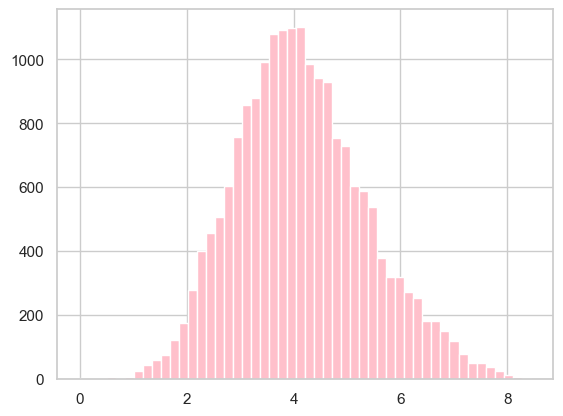

In [120]:
plt.hist(np.log10(df.loc[df['viewCount'] > 0, 'viewCount']), bins=50, color='pink')
plt.show()

<Axes: xlabel='video_age', ylabel='music_style'>

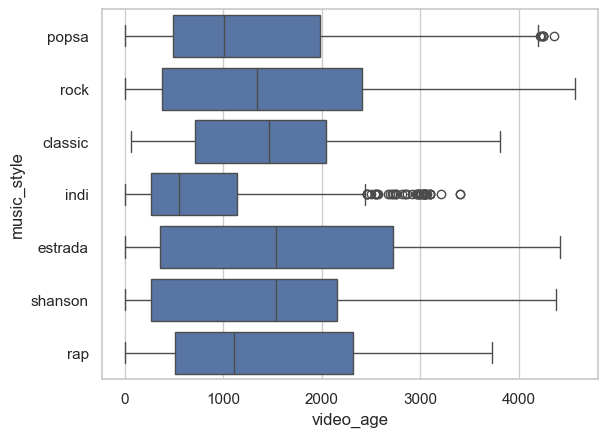

In [121]:
sns.boxplot(data = df, x = 'video_age', y = 'music_style')

<details>
<summary><strong>Ориентиры для самопроверки</strong></summary>

После логарифмирования распределение просмотров должно стать значительно компактнее и менее правосторонне скошенным.

Медианный возраст по жанрам, от меньшего к большему:

| Жанр | Медианный возраст, дней |
|---|---:|
| `indi` | 555 |
| `popsa` | 1 005 |
| `rap` | 1 110 |
| `rock` | 1 347 |
| `classic` | 1 463 |
| `estrada` | 1 537 |
| `shanson` | 1 540 |

Самые молодые типичные видео относятся к `indi`, самые старые — к `shanson`.

</details>

## Задание 9. Связи между показателями

Рассчитайте матрицу коэффициентов корреляции Пирсона для колонок:

- `viewCount` — количество просмотров;
- `likeCount` — количество лайков;
- `commentCount` — количество комментариев;
- `dislikeCount` — количество дизлайков.

Визуализируйте матрицу в виде тепловой карты с подписанными значениями. Найдите самую сильную связь между двумя разными показателями и кратко объясните, почему корреляция сама по себе не доказывает причинно-следственную связь.

<Axes: >

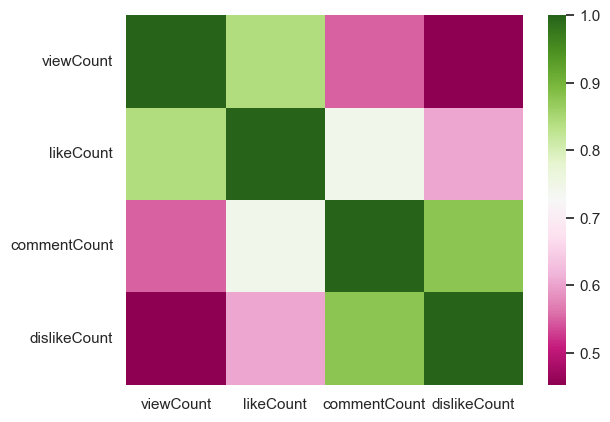

In [122]:
df_corr = df[['viewCount', 'likeCount', 'commentCount', 'dislikeCount']].corr(method='pearson')
sns.heatmap(df_corr, cmap = 'PiYG')

<details>
<summary><strong>Результат для самопроверки</strong></summary>

Матрица, округлённая до трёх знаков:

| | `viewCount` | `likeCount` | `commentCount` | `dislikeCount` |
|---|---:|---:|---:|---:|
| `viewCount` | 1,000 | 0,841 | 0,550 | 0,453 |
| `likeCount` | 0,841 | 1,000 | 0,744 | 0,603 |
| `commentCount` | 0,550 | 0,744 | 1,000 | 0,876 |
| `dislikeCount` | 0,453 | 0,603 | 0,876 | 1,000 |

Самая сильная связь между разными показателями — у `commentCount` и `dislikeCount`: примерно 0,876. Корреляция описывает совместное изменение, но не устанавливает направление влияния и не исключает воздействие третьих факторов, например общей популярности видео.

</details>

## Задание 10. Симуляция случайной величины

Смоделируйте 10 000 наблюдений из нормального распределения со средним 100 и стандартным отклонением 15. Для воспроизводимости используйте генератор `np.random.default_rng(42)`.

Для полученной выборки найдите среднее, медиану, выборочное стандартное отклонение, 95-й процентиль и долю наблюдений строго больше 130. Постройте гистограмму и отметьте на ней среднее и медиану вертикальными линиями. Сравните выборочные характеристики с параметрами заданного распределения.

In [123]:
rng = np.random.default_rng(42)
sample = rng.normal(loc=100, scale=15, size=10_000)

print(f'Среднее: {sample.mean()}')
print(f'Медиана: {np.median(sample)}')
print(f'Выборочное стандартное отклонение: {sample.std(ddof=1)}')
print(f'95-й процентиль: {np.quantile(sample, 0.95)}')
print(f'Доля наблюдений больше 130: {(sample > 130).mean()}')

Среднее: 99.84625186878984
Медиана: 99.80248744866078
Выборочное стандартное отклонение: 15.095041298990308
95-й процентиль: 124.64109992925111
Доля наблюдений больше 130: 0.0226


<details>
<summary><strong>Результат для самопроверки</strong></summary>

- среднее: 99,8463;
- медиана: 99,8025;
- выборочное стандартное отклонение: 15,0950;
- 95-й процентиль: 124,6411;
- доля значений больше 130: 0,0226, или 2,26%.

Выборочные среднее и стандартное отклонение близки к заданным параметрам 100 и 15; небольшие отличия возникают из-за случайности выборки.

</details>

## 3. Финальная проверка

Перед сдачей убедитесь, что:

- все десять заданий выполнены;
- ответы снабжены понятными подписями;
- графики имеют заголовки и подписи осей;
- содержательные выводы написаны своими словами;
- после перезапуска ядра все ячейки выполняются сверху вниз без ошибок.